# PaddleOCR

In [ ]:
!curl -L -o ~/invoices-ocr.zip https://www.kaggle.com/api/v1/datasets/download/osamahosamabdellatif/high-quality-invoice-images-for-ocr
!unzip ~/invoices-ocr.zip -d /content/invoices

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 1165M  100 1165M    0     0   160M      0  0:00:07  0:00:07 --:--:--  170M


In [ ]:
%pip uninstall -y paddlepaddle paddlepaddle-gpu

# %pip install --no-cache-dir --timeout 1000 --retries 10 \
#     paddlepaddle-gpu==3.3.0 \
#     -i https://www.paddlepaddle.org.cn/packages/stable/cu130/

%pip install -U paddleocr

Found existing installation: paddlepaddle 3.2.0
Uninstalling paddlepaddle-3.2.0:
  Successfully uninstalled paddlepaddle-3.2.0
Looking in indexes: https://www.paddlepaddle.org.cn/packages/stable/cu130/
     ━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━ 0.6/1.4 GB 564.8 kB/s eta 0:23:33m
ERROR: Wheel 'paddlepaddle-gpu' located at /tmp/pip-unpack-7sdu5hkm/paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl is invalid.


In [3]:
!wget --continue \
  --timeout=1000 \
  --tries=20 \
  --retry-connrefused \
  -O /content/paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl \
  "https://paddle-whl.cdn.bcebos.com/stable/cu130/paddlepaddle-gpu/paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl"

--2026-10-05 19:30:32--  https://paddle-whl.cdn.bcebos.com/stable/cu130/paddlepaddle-gpu/paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl
Resolving paddle-whl.cdn.bcebos.com (paddle-whl.cdn.bcebos.com)... 

119.41.82.38, 117.21.233.38, 117.24.165.38, ...
Connecting to paddle-whl.cdn.bcebos.com (paddle-whl.cdn.bcebos.com)|119.41.82.38|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1364142942 (1.3G) [application/octet-stream]
Saving to: ‘/content/paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl’

/content/paddlepadd 100%[===================>]   1.27G  6.00MB/s    in 3m 27s  

2026-10-05 19:34:00 (6.30 MB/s) - ‘/content/paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl’ saved [1364142942/1364142942]



In [4]:
!ls -lh /content/paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl

-rw-r--r-- 1 root root 1.3G Jan 13  2026 /content/paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl


In [5]:
!pip install --no-cache-dir /content/paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl

Processing ./paddlepaddle_gpu-3.3.0-cp313-cp313-linux_x86_64.whl
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 420.9/420.9 MB 107.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 286.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.6/348.6 MB 78.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 71.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.3/195.3 MB 89.5 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: nvidia-cusparselt-cu13
    Found existing installation: nvidia-cusparselt-cu13 0.8.0
    Uninstalling nvidia-cusparselt-cu13-0.8.0:
      Successfully uninstalled nvidia-cusparselt-cu13-0.8.0
  Attempting uninstall: nvidia-nccl-cu13
    Found existing installation: nvidia-nccl-cu13 2.28.9
    Uninstalling nvidia-nccl-cu13-2.28.9:
      Successfully uninstalled nvidia-nccl-cu13-2.28.9
  Attempting uninstall: nvidia-cuda-runtime
    Found existing installation: nvidi

In [6]:
!nvidia-smi

Mon Oct  5 19:35:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   30C    P0             46W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [1]:
import torch
import paddle

print("Torch:", torch.__version__)
print("Torch CUDA:", torch.cuda.is_available())
print("Paddle:", paddle.__version__)
print("Paddle CUDA:", paddle.is_compiled_with_cuda())
print("Paddle GPUs:", paddle.device.cuda.device_count())

assert torch.cuda.is_available()
assert paddle.is_compiled_with_cuda()
assert paddle.device.cuda.device_count() > 0

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Torch: 2.11.0+cu130
Torch CUDA: True
Paddle: 3.3.0
Paddle CUDA: True
Paddle GPUs: 1


In [2]:
from paddleocr import PaddleOCR

ocr = PaddleOCR(
    device="gpu:0",
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)

Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/root/.paddlex/official_models/PP-OCRv6_medium_rec`.


In [3]:
import os
import json
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
from pathlib import Path
import pandas as pd
from torch.utils.data import Dataset
from PIL import Image
from torchvision import transforms
import torch
import paddleocr

In [55]:
!ls -la /content/invoices/batch_3/batch_1/batch1_1

total 98972
drwxr-xr-x 2 root root  20480 Oct  5 19:13 .
drwxr-xr-x 5 root root   4096 Oct  5 19:13 ..
-rw-r--r-- 1 root root 254400 May  9  2025 batch1-0001.jpg
-rw-r--r-- 1 root root 220646 May  9  2025 batch1-0002.jpg
-rw-r--r-- 1 root root 192117 May  9  2025 batch1-0003.jpg
-rw-r--r-- 1 root root 221526 May  9  2025 batch1-0004.jpg
-rw-r--r-- 1 root root 212125 May  9  2025 batch1-0005.jpg
-rw-r--r-- 1 root root 197089 May  9  2025 batch1-0006.jpg
-rw-r--r-- 1 root root 255055 May  9  2025 batch1-0007.jpg
-rw-r--r-- 1 root root 208864 May  9  2025 batch1-0008.jpg
-rw-r--r-- 1 root root 166334 May  9  2025 batch1-0009.jpg
-rw-r--r-- 1 root root 174190 May  9  2025 batch1-0010.jpg
-rw-r--r-- 1 root root 175665 May  9  2025 batch1-0011.jpg
-rw-r--r-- 1 root root 199060 May  9  2025 batch1-0012.jpg
-rw-r--r-- 1 root root 198437 May  9  2025 batch1-0013.jpg
-rw-r--r-- 1 root root 157856 May  9  2025 batch1-0014.jpg
-rw-r--r-- 1 root root 226316 May  9  2025 batch1-0015.jpg
-rw-r--r-- 1

In [4]:
INVOICES_PATH = os.path.join("/content", "invoices")

In [38]:
!apt-get update -qq
!apt-get install -y -qq tree

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tree.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../tree_2.1.1-2ubuntu3.24.04.2_amd64.deb ...
Unpacking tree (2.1.1-2ubuntu3.24.04.2) ...
Setting up tree (2.1.1-2ubuntu3.24.04.2) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [40]:
!tree /content/invoices/ -d

/content/invoices/
├── batch_1
│   └── batch_1
│       ├── batch1_1
│       ├── batch1_2
│       └── batch1_3
├── batch_2
│   └── batch_2
│       ├── batch2_1
│       ├── batch2_2
│       └── batch2_3
└── batch_3
    ├── batch_1
    │   ├── batch1_1
    │   ├── batch1_2
    │   └── batch1_3
    ├── batch_2
    │   ├── batch2_1
    │   ├── batch2_2
    │   └── batch2_3
    └── batch_3
        ├── batch3_1
        ├── batch3_2
        ├── batch3_3
        ├── batch3_4
        └── batch3_5

26 directories


In [47]:
list(INVOICES_PATH.rglob("*.csv"))

[PosixPath('/content/invoices/batch_1/batch_1/batch1_3.csv'),
 PosixPath('/content/invoices/batch_1/batch_1/batch1_1.csv'),
 PosixPath('/content/invoices/batch_1/batch_1/batch1_2.csv')]

In [42]:
from pathlib import Path
import pandas as pd

INVOICES_PATH = Path("/content/invoices")

dfs = []

for csv_path in sorted(INVOICES_PATH.rglob("*.csv")):
    image_dir = csv_path.parent / csv_path.stem

    if not image_dir.is_dir():
        print(f"Skipping: image directory not found for {csv_path}")
        continue

    df_part = pd.read_csv(csv_path)

    if "File Name" not in df_part.columns:
        print(f"Skipping: 'File Name' column not found in {csv_path}")
        continue

    # Keep provenance because folder names repeat in different batches.
    df_part["subdir"] = csv_path.stem
    df_part["source_group"] = str(csv_path.parent.relative_to(INVOICES_PATH))
    df_part["csv_path"] = str(csv_path)

    df_part["path"] = df_part["File Name"].map(
        lambda filename: str(image_dir / filename)
    )

    dfs.append(df_part)

if not dfs:
    raise RuntimeError("No valid CSV files were found")

df = pd.concat(dfs, ignore_index=True)

# Normalize column names.
df.columns = (
    df.columns
    .str.strip()
    .str.replace(r"(?<=[a-z0-9])(?=[A-Z])", "_", regex=True)
    .str.replace(r"[^a-zA-Z0-9]+", "_", regex=True)
    .str.strip("_")
    .str.lower()
)

df.reset_index(drop=True, inplace=True)

In [44]:
image_exists = df["path"].map(lambda path: Path(path).exists())

print(f"CSV files loaded: {len(dfs)}")
print(f"Total records: {len(df):,}")
print(f"Missing images: {(~image_exists).sum():,}")
print(f"Duplicate paths: {df['path'].duplicated().sum():,}")

CSV files loaded: 3
Total records: 1,414
Missing images: 0
Duplicate paths: 1


In [57]:
for csv_path in sorted(INVOICES_PATH.rglob("*.csv")):
    image_dir = csv_path.parent / csv_path.stem
    csv_rows = len(pd.read_csv(csv_path))
    image_count = sum(
        path.suffix.lower() in [".jpg"]
        for path in image_dir.iterdir()
        if path.is_file()
    )

    print(
        csv_path.name,
        "rows:", csv_rows,
        "images:", image_count,
    )

batch1_1.csv rows: 499 images: 499
batch1_2.csv rows: 426 images: 501
batch1_3.csv rows: 489 images: 489


In [58]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}

for csv_path in sorted(INVOICES_PATH.rglob("*.csv")):
    image_dir = csv_path.parent / csv_path.stem
    part = pd.read_csv(csv_path)

    csv_names = part["File Name"].astype(str)
    csv_name_set = set(csv_names)

    image_names = {
        path.name
        for path in image_dir.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    }

    images_without_annotations = sorted(image_names - csv_name_set)
    annotations_without_images = sorted(csv_name_set - image_names)
    duplicate_annotations = sorted(
        csv_names[csv_names.duplicated(keep=False)].unique()
    )

    print(f"\n{csv_path.name}")
    print(f"  CSV rows: {len(part)}")
    print(f"  Unique CSV filenames: {csv_names.nunique()}")
    print(f"  Images: {len(image_names)}")
    print(f"  Images without annotations: {len(images_without_annotations)}")
    print(f"  Annotations without images: {len(annotations_without_images)}")
    print(f"  Duplicate annotation filenames: {duplicate_annotations}")

    if images_without_annotations:
        print("  First unannotated images:", images_without_annotations[:10])


batch1_1.csv
  CSV rows: 499
  Unique CSV filenames: 499
  Images: 499
  Images without annotations: 0
  Annotations without images: 0
  Duplicate annotation filenames: []

batch1_2.csv
  CSV rows: 426
  Unique CSV filenames: 425
  Images: 501
  Images without annotations: 76
  Annotations without images: 0
  Duplicate annotation filenames: ['batch1-0575.jpg']
  First unannotated images: ['batch1-0576.jpg', 'batch1-0577.jpg', 'batch1-0578.jpg', 'batch1-0579.jpg', 'batch1-0580.jpg', 'batch1-0581.jpg', 'batch1-0582.jpg', 'batch1-0583.jpg', 'batch1-0584.jpg', 'batch1-0585.jpg']

batch1_3.csv
  CSV rows: 489
  Unique CSV filenames: 489
  Images: 489
  Images without annotations: 0
  Annotations without images: 0
  Duplicate annotation filenames: []


In [61]:
from IPython.display import display

In [62]:
duplicate = df[
    (df["file_name"] == "batch1-0575.jpg")
    & (df["subdir"] == "batch1_2")
]

display(
    duplicate[
        ["file_name", "json_data", "ocred_text", "csv_path", "path"]
    ]
)

,file_name,json_data,ocred_text,csv_path,path
574,batch1-0575.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Grego...",Invoice no: 48223084 Date of issue: 12/05/2018...,/content/invoices/batch_1/batch_1/batch1_2.csv,/content/invoices/batch_1/batch_1/batch1_2/bat...
575,batch1-0575.jpg,"\n{\n ""invoice"": {\n ""client_name"": ""Grego...",Invoice no: 48223084 Date of issue: 12/05/2018...,/content/invoices/batch_1/batch_1/batch1_2.csv,/content/invoices/batch_1/batch_1/batch1_2/bat...


In [63]:
print("Rows:", len(duplicate))
print("Unique JSON values:", duplicate["json_data"].nunique(dropna=False))
print("Unique OCR texts:", duplicate["ocred_text"].nunique(dropna=False))

Rows: 2
Unique JSON values: 1
Unique OCR texts: 1


In [65]:
annotated_df = (
    df.drop_duplicates(subset=["path"], keep="first")
    .reset_index(drop=True)
)

assert len(annotated_df) == 1413
assert annotated_df["path"].is_unique

In [12]:
!ls -la /content/invoices/batch_1/batch_1/

total 3064
drwxr-xr-x 5 root root    4096 Oct  5 19:13 .
drwxr-xr-x 3 root root    4096 Oct  5 19:13 ..
drwxr-xr-x 2 root root   20480 Oct  5 19:13 batch1_1
-rw-r--r-- 1 root root 1077585 May  9  2025 batch1_1.csv
drwxr-xr-x 2 root root   20480 Oct  5 19:13 batch1_2
-rw-r--r-- 1 root root  929193 May  9  2025 batch1_2.csv
drwxr-xr-x 2 root root   20480 Oct  5 19:13 batch1_3
-rw-r--r-- 1 root root 1046341 May  9  2025 batch1_3.csv


In [13]:
row = df.iloc[5]
result = ocr.predict(row['path'])

In [26]:
row['OCRed Text']

'Invoice no: 57290992 Date of issue: 10/03/2011 Seller: Client: Adams PLC Johnson, Daniels and Ramirez USS Moon 6889 Oliver Summit FPO AA 34591 South Ebony, NY 23978 Tax Id: 964-98-1799 Tax Id: 925-71-0496 IBAN: GB3OOLCJ81769735097340 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth 25"x25 Marble Black Top 5,00 each 2 789,00 13 945,00 10% 15 339,50 custom Table Carnelian Marquetry Art Halloween Gift 2 7\'x4 Blue Random Marble 3,00 each 8 194,09 24 582,27 10% 27 040,50 Dining Hallway Table Top Lapis Lazuli Decor E947A 3 6\'x3\' White Marble Dining Table 4,00 each 6 408,49 25 633,96 10% 28 197,36 Top Multi Inlay Floral Elephant Art Decor H4952 SUMMARY VAT [%] Net worth VAT Gross worth 10% 64 161,23 6 416,12 70 577,35 Total $ 64 161,23 $ 6 416,12 $ 70 577,35 Inlay'

In [24]:
result[0]['rec_texts']

['Invoice no: 57290992',
 'Date of issue:',
 '10/03/2011',
 'Seller:',
 'Client:',
 'Adams PLC',
 'Johnson, Daniels and Ramirez',
 'USS Moon',
 '6889 Oliver Summit',
 'FPO AA 34591',
 'South Ebony, NY 23978',
 'Tax Id: 964-98-1799',
 'Tax Id: 925-71-0496',
 'IBAN: GB30OLCJ81769735097340',
 'ITEMS',
 'No.',
 'Description',
 'Qty',
 'UM',
 'Net price',
 'Net worth',
 'VAT [%]',
 'Gross',
 'worth',
 '1.',
 '25"x25" Marble Black Top',
 '5,00',
 'each',
 '2 789,00',
 '13 945,00',
 '10%',
 '15 339,50',
 'custom Table Carnelian',
 'Marquetry Art Halloween Gift',
 '2.',
 "7'x4' Blue Random Marble",
 '3,00',
 'each',
 '8 194,09',
 '24 582,27',
 '10%',
 '27 040,50',
 'Dining Hallway Table Top Lapis',
 'Lazuli Inlay Decor E947A',
 '3.',
 "6'x3' White Marble Dining Table",
 '4,00',
 'each',
 '6 408,49',
 '25 633,96',
 '10%',
 '28 197,36',
 'Top Multi Inlay Floral Elephant',
 'Art Decor H4952',
 'SUMMARY',
 'VAT [%]',
 'Net worth',
 'VAT',
 'Gross worth',
 '10%',
 '64 161,23',
 '6 416,12',
 '70 577

In [14]:
for res in result:  
    res.print()  
    res.save_to_img("output")  
    res.save_to_json("output")  

{'res': {'input_path': '/content/invoices/batch_1/batch_1/batch1_1/batch1-0105.jpg', 'page_index': None, 'model_settings': {'use_doc_preprocessor': False, 'use_textline_orientation': False}, 'dt_polys': array([[[ 133,   73],
        ...,
        [ 133,  104]],

       ...,

       [[1352, 1512],
        ...,
        [1352, 1539]]], dtype=int16), 'text_det_params': {'limit_side_len': 64, 'limit_type': 'min', 'thresh': 0.3, 'max_side_limit': 4000, 'box_thresh': 0.6, 'unclip_ratio': 1.5}, 'text_type': 'general', 'textline_orientation_angles': array([-1, ..., -1]), 'text_rec_score_thresh': 0.0, 'return_word_box': False, 'rec_texts': ['Invoice no: 57290992', 'Date of issue:', '10/03/2011', 'Seller:', 'Client:', 'Adams PLC', 'Johnson, Daniels and Ramirez', 'USS Moon', '6889 Oliver Summit', 'FPO AA 34591', 'South Ebony, NY 23978', 'Tax Id: 964-98-1799', 'Tax Id: 925-71-0496', 'IBAN: GB30OLCJ81769735097340', 'ITEMS', 'No.', 'Description', 'Qty', 'UM', 'Net price', 'Net worth', 'VAT [%]', 'Gros

### 1. Create the clean annotated dataset

In [67]:
annotated_df = (
    df.drop_duplicates(subset=["path"], keep="first")
    .reset_index(drop=True)
)

assert len(annotated_df) == 1413
assert annotated_df["path"].is_unique
assert annotated_df["path"].map(lambda p: Path(p).exists()).all()

print("Annotated invoices:", len(annotated_df))

Annotated invoices: 1413


### 2. Parse and validate `json_data`

In [68]:
import json

def parse_json(value):
    try:
        return json.loads(value)
    except (TypeError, json.JSONDecodeError):
        return None

annotated_df["target"] = annotated_df["json_data"].map(parse_json)

print("Invalid JSON:", annotated_df["target"].isna().sum())
annotated_df["target"].head()

Invalid JSON: 0


,target
0,"{'invoice': {'client_name': 'Clark-Foster', 'c..."
1,"{'invoice': {'client_name': 'Williams, Schneid..."
2,"{'invoice': {'client_name': 'Hester Inc', 'cli..."
3,"{'invoice': {'client_name': 'Olson, Cisneros a..."
4,"{'invoice': {'client_name': 'Wilson-Wilson', '..."


#### Inspect top-level schema

In [69]:
annotated_df["top_level_keys"] = annotated_df["target"].map(
    lambda obj: tuple(sorted(obj.keys())) if obj else None
)

annotated_df["top_level_keys"].value_counts()

,count
top_level_keys,
"(invoice, items, payment_instructions, subtotal)",1413


#### Canonicalize JSON for future text-to-JSON training:

In [70]:
annotated_df["target_text"] = annotated_df["target"].map(
    lambda obj: json.dumps(
        obj,
        ensure_ascii=False,
        sort_keys=True,
        separators=(",", ":"),
    )
)

### 3. Manually validate 30–50 examples

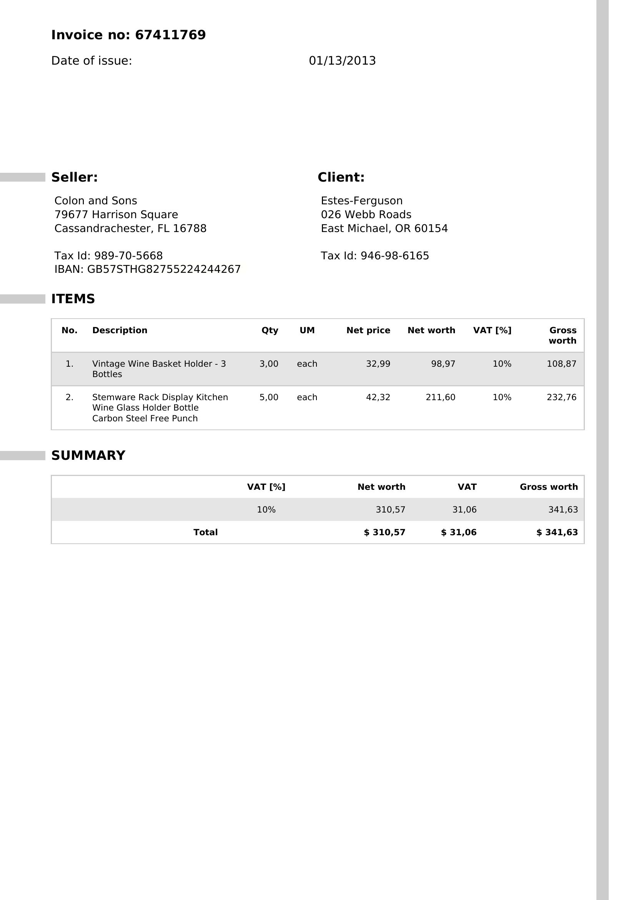

REFERENCE TEXT:
Invoice no: 67411769 Date of issue: 01/13/2013 Seller: Client: Colon and Sons Estes-Ferguson 79677 Harrison Square 026 Webb Roads Cassandrachester, FL 16788 East Michael, OR 60154 Tax Id: 989-70-5668 Tax Id: 946-98-6165 IBAN: GBSZSTHG82755224244267 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Vintage Wine Basket Holder 3 3,00 each 32,99 98,97 10% 108,87 Bottles 2 Stemware Rack Display Kitchen 5,00 each 42,32 211,60 10% 232,76 Wine Glass Holder Bottle Carbon Steel Free Punch SUMMARY VAT [%] Net worth VAT Gross worth 10% 310,57 31,06 341,63 Total $ 310,57 $ 31,06 $ 341,63

JSON:
{
  "invoice": {
    "client_name": "Estes-Ferguson",
    "client_address": "026 Webb Roads\nEast Michael, OR 60154",
    "seller_name": "Colon and Sons",
    "seller_address": "79677 Harrison Square\nCassandrachester, FL 16788",
    "invoice_number": "67411769",
    "invoice_date": "01/13/2013",
    "due_date": ""
  },
  "items": [
    {
      "description": "Vintage Wine 

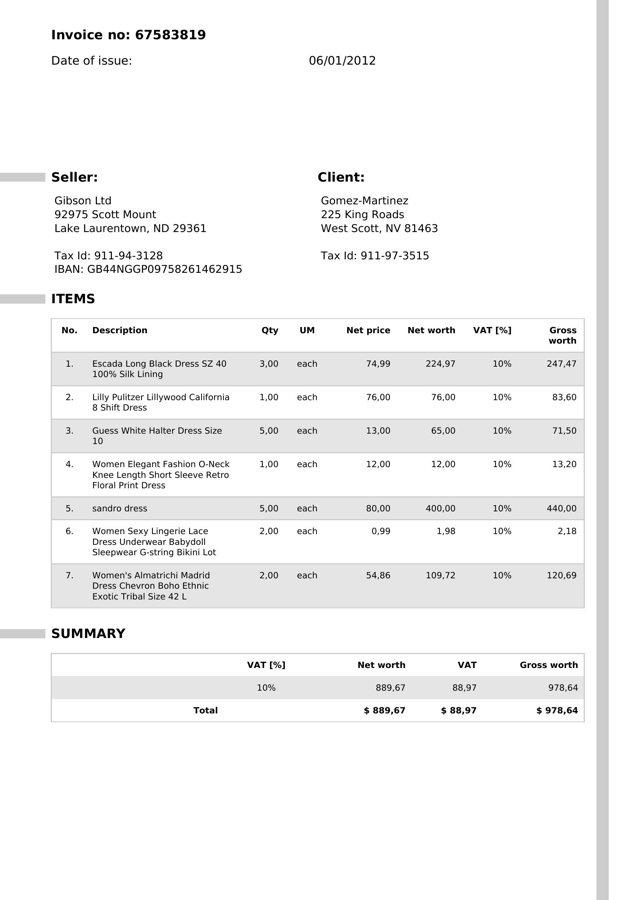

REFERENCE TEXT:
Invoice no: 67583819 Date of issue: 06/01/2012 Seller: Client: Gibson Ltd Gomez-Martinez 92975 Scott Mount 225 King Roads Lake Laurentown; ND 29361 West Scott, NV 81463 Tax Id: 911-94-3128 Tax Id: 911-97-3515 IBAN: GBAANGGPO9758261462915 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Escada Long Black Dress SZ 40 3,00 each 74,99 224,97 10% 247,47 100% Silk Lining 2 Lilly Pulitzer Lillywood California 1,00 each 76,00 76,00 10% 83,60 8 Shift Dress 3 Guess White Halter Dress Size 5,00 each 13,00 65,00 10% 71,50 10 Women Elegant Fashion O-Neck 1,00 each 12,00 12,00 10% 13,20 Knee Length Short Sleeve Retro Floral Print Dress 5 sandro dress 5,00 each 80,00 400,00 10% 440,00 6 Women Lingerie Lace 2,00 each 0,99 1,98 10% 2,18 Dress Underwear Babydoll Sleepwear G-string Bikini Lot Women's Almatrichi Madrid 2,00 each 54,86 109,72 10% 120,69 Dress Chevron Boho Ethnic Exotic Tribal Size 42 SUMMARY VAT [%] Net worth VAT Gross worth 10% 889,67 88,97 978,64 Total

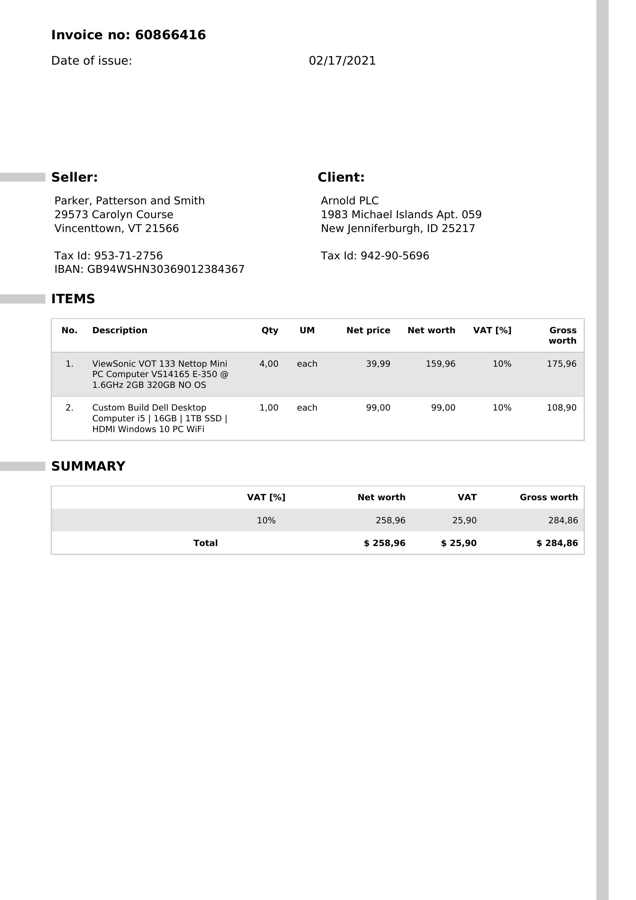

REFERENCE TEXT:
Invoice no: 60866416 Date of issue: 02/17/2021 Seller: Client: Parker, Patterson and Smith Arnold PLC 29573 Carolyn Course 1983 Michael Islands Apt. 059 Vincenttown, VT 21566 New Jenniferburgh, ID 25217 Tax Id: 953-71-2756 Tax Id: 942-90-5696 IBAN: GB94WSHN30369012384367 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth 1. ViewSonic VOT 133 Nettop Mini 4,00 each 39,99 159,96 10% 175,96 PC Computer VS14165 E-350 1.6GHz 2GB 320GB NO OS 2 Custom Build Dell Desktop 1,00 each 99,00 99,00 10% 108,90 Computer i5 16GB 1TB SSD | HDMI Windows 10 PC WiFi SUMMARY VAT [%] Net worth VAT Gross worth 10% 258,96 25,90 284,86 Total $ 258,96 $ 25,90 $ 284,86

JSON:
{
  "invoice": {
    "client_name": "Arnold PLC",
    "client_address": "1983 Michael Islands Apt. 059\nNew Jenniferburgh, ID 25217",
    "seller_name": "Parker, Patterson and Smith",
    "seller_address": "29573 Carolyn Course\nVincenttown, VT 21566",
    "invoice_number": "60866416",
    "invoice_date": "02

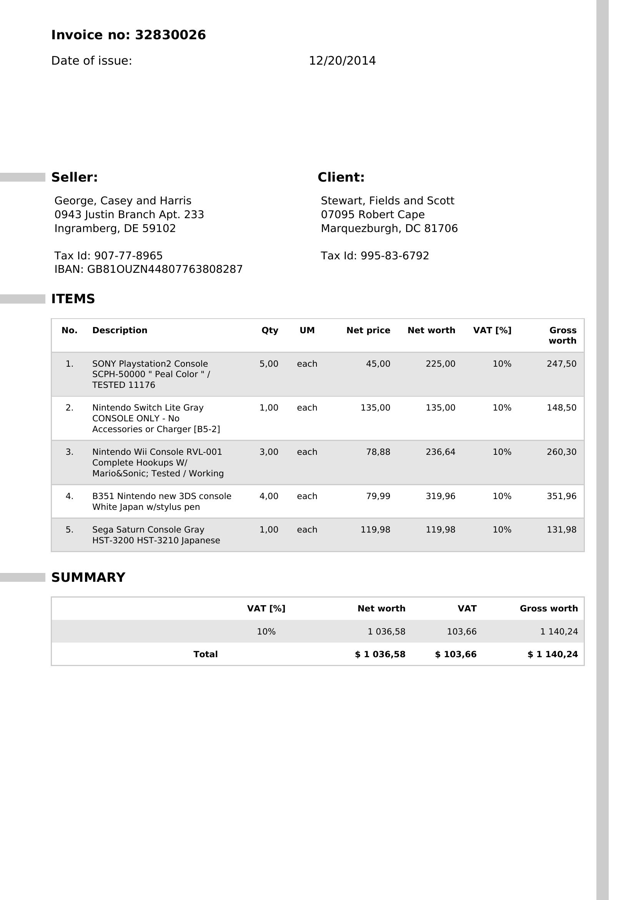

REFERENCE TEXT:
Invoice no: 32830026 Date of issue: 12/20/2014 Seller: Client: George, Casey and Harris Stewart, Fields and Scott 0943 Justin Branch Apt: 233 07095 Robert Cape Ingramberg, DE 59102 Marquezburgh, DC 81706 Tax Id: 907-77-8965 Tax Id: 995-83-6792 IBAN: GB8IOUZN44807763808287 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth SONY Playstation2 Console 5,00 each 45,00 225,00 10% 247,50 SCPH-5oooo Peal Color TESTED 11176 2 Nintendo Switch Lite Gray 1,00 each 135,00 135,00 10% 148,50 CONSOLE ONLY No Accessories or Charger [B5-2] 3 Nintendo Wii Console RVL-001 3,00 each 78,88 236,64 10% 260,30 Complete Hookups W/ Mario&Sonic; Tested Working B351 Nintendo new 3DS console 4,00 each 79,99 319,96 10% 351,96 White Japan wlstylus pen 5 Saturn Console Gray 1,00 each 119,98 119,98 10% 131,98 HST-3200 HST-3210 Japanese SUMMARY VAT [%] Net worth VAT Gross worth 10% 1 036,58 103,66 1 140,24 Total $ 1 036,58 $ 103,66 $ 1 140,24 Sega

JSON:
{
  "invoice": {
    "client_nam

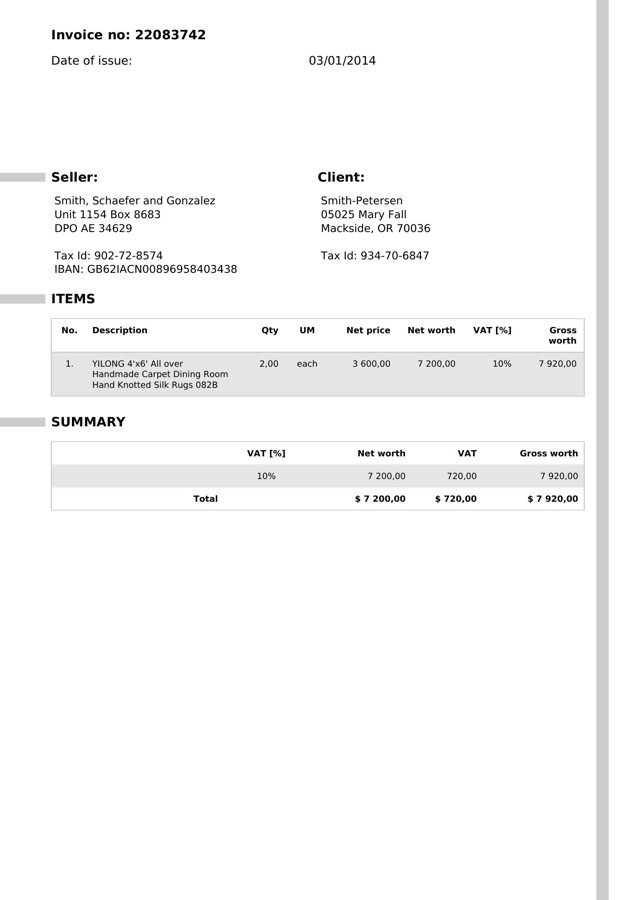

REFERENCE TEXT:
Invoice no: 22083742 Date of issue: 03/01/2014 Seller: Client: Smith, Schaefer and Gonzalez Smith-Petersen Unit 1154 Box 8683 05025 Mary Fall DPO AE 34629 Mackside, OR 70036 Tax Id: 902-72-8574 Tax Id: 934-70-6847 IBAN: GB6ZIACN00896958403438 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth YILONG 4'x6' All over 2,00 each 3 600,00 7 200,00 10% 7 920,00 Handmade Carpet Dining Room Hand Knotted Silk Rugs 082B SUMMARY VAT [%] Net worth VAT Gross worth 10% 7 200,00 720,00 7 920,00 Total $ 7 200,00 $ 720,00 $ 7 920,00

JSON:
{
  "invoice": {
    "client_name": "Smith-Petersen",
    "client_address": "05025 Mary Fall\nMackside, OR 70036",
    "seller_name": "Smith, Schaefer and Gonzalez",
    "seller_address": "Unit 1154 Box 8683\nDPO AE 34629",
    "invoice_number": "22083742",
    "invoice_date": "03/01/2014",
    "due_date": ""
  },
  "items": [
    {
      "description": "YILONG 4'x6' All over\nHandmade Carpet Dining Room\nHand Knotted Silk Rugs 082B",

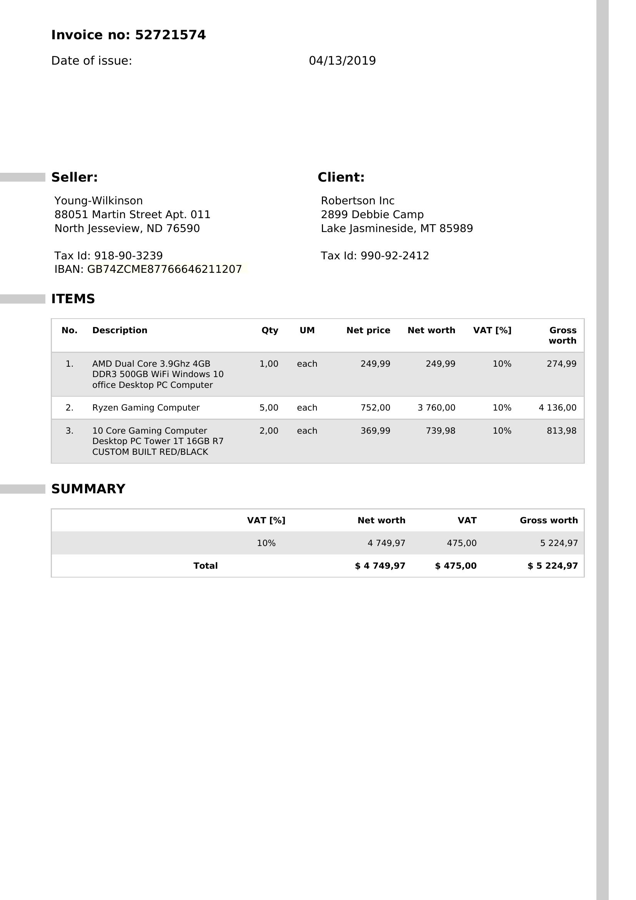

REFERENCE TEXT:
Invoice no: 52721574 Date of issue: 04/13/2019 Seller: Client: Young-Wilkinson Robertson Inc 88051 Martin Street Apt: 011 2899 Debbie Camp North Jesseview, ND 76590 Lake Jasmineside, MT 85989 Tax Id: 918-90-3239 Tax Id: 990-92-2412 IBAN: GBZ4ZCME87766646211207 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth AMD Dual Core 3.9Ghz 4GB 1,00 each 249,99 249,99 10% 274,99 DDR3 S00GB WiFi Windows 10 office Desktop PC Computer 2 Ryzen Gaming Computer 5,00 each 752,00 3 760,00 10% 136,00 3 10 Core Gaming Computer 2,00 each 369,99 739,98 10% 813,98 Desktop PC Tower 1T 16GB R7 CUSTOM BUILT REDIBLACK SUMMARY VAT [%] Net worth VAT Gross worth 10% 4 749,97 475,00 5 224,97 Total $ 4 749,97 $ 475,00 $ 5 224,97

JSON:
{
  "invoice": {
    "client_name": "Robertson Inc",
    "client_address": "2899 Debbie Camp\nLake Jasmineside, MT 85989",
    "seller_name": "Young-Wilkinson",
    "seller_address": "88051 Martin Street Apt. 011\nNorth Jesseview, ND 76590",
    "invoi

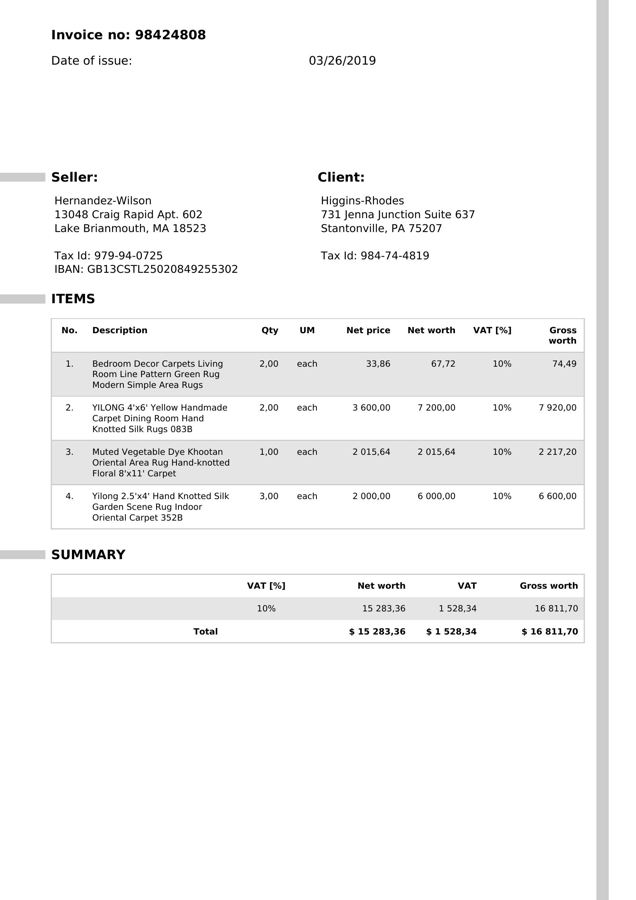

REFERENCE TEXT:
Invoice no: 98424808 Date of issue: 03/26/2019 Seller: Client: Hernandez-Wilson Higgins-Rhodes 13048 Craig Rapid Apt: 602 731 Jenna Junction Suite 637 Lake Brianmouth, MA 18523 Stantonville, PA 75207 Tax Id: 979-94-0725 Tax Id: 984-74-4819 IBAN: GB13CSTL25020849255302 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Bedroom Decor Carpets Living 2,00 each 33,86 67,72 10% 74,49 Room Line Pattern Green Rug Modern Simple Area Rugs 2 YILONG 4'x6' Yellow Handmade 2,00 each 3 600,00 7 200,00 10% 920,00 Carpet Dining Room Hand Knotted Silk Rugs 083B 3 Muted Vegetable Dye Khootan 1,00 each 2 015,64 2 015,64 10% 2 217,20 Oriental Area Rug Hand-knotted Floral 8'xl1 Carpet Yilong 2.5'x4 Hand Knotted Silk 3,00 each 2 000,00 6 000,00 10% 6 600,00 Garden Scene Rug Indoor Oriental Carpet 352B SUMMARY VAT [%] Net worth VAT Gross worth 10% 15 283,36 1 528,34 16 811,70 Total $ 15 283,36 $ 1 528,34 $ 16 811,70

JSON:
{
  "invoice": {
    "client_name": "Higgins-Rhodes",

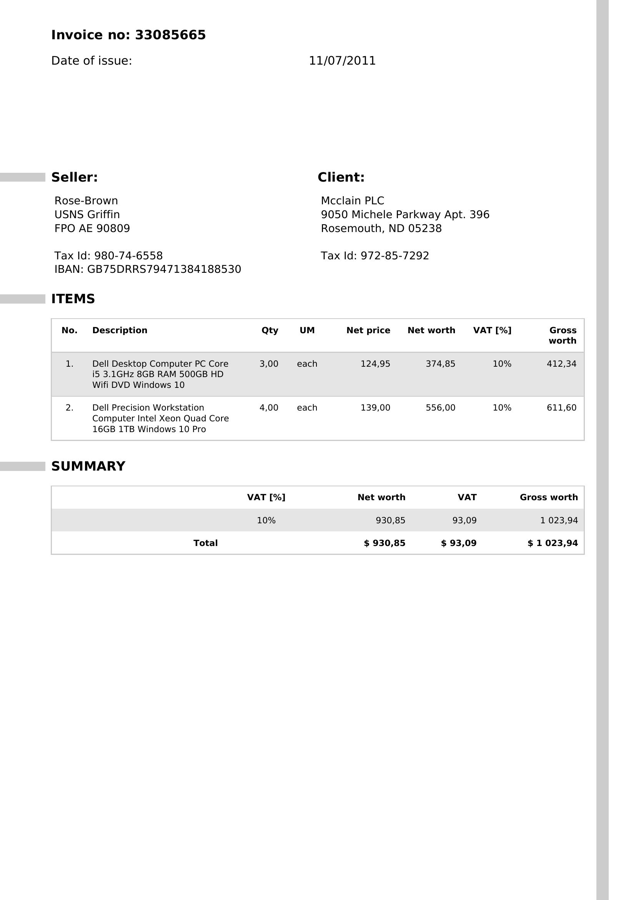

REFERENCE TEXT:
Invoice no: 33085665 Date of issue: 11/07/2011 Seller: Client: Rose-Brown Mcclain PLC USNS Griffin 9050 Michele Parkway Apt. 396 FPO AE 90809 Rosemouth; ND 05238 Tax Id: 980-74-6558 Tax Id: 972-85-7292 IBAN: GBZSDRRS79471384188530 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Dell Desktop Computer PC Core 3,00 each 124,95 374,85 10% 412,34 i5 3.1GHz 8GB RAM S00GB HD Wifi DVD Windows 10 2 Dell Precision Workstation 4,00 each 139,00 556,00 10% 611,60 Computer Intel Xeon Quad Core 16GB 1TB Windows 10 Pro SUMMARY VAT [%] Net worth VAT Gross worth 10% 930,85 93,09 1 023,94 Total $ 930,85 $ 93,09 $ 1 023,94

JSON:
{
  "invoice": {
    "client_name": "Mcclain PLC",
    "client_address": "9050 Michele Parkway Apt. 396\nRosemouth, ND 05238",
    "seller_name": "Rose-Brown",
    "seller_address": "USNS Griffin\nFPO AE 90809",
    "invoice_number": "33085665",
    "invoice_date": "11/07/2011",
    "due_date": ""
  },
  "items": [
    {
      "description": "

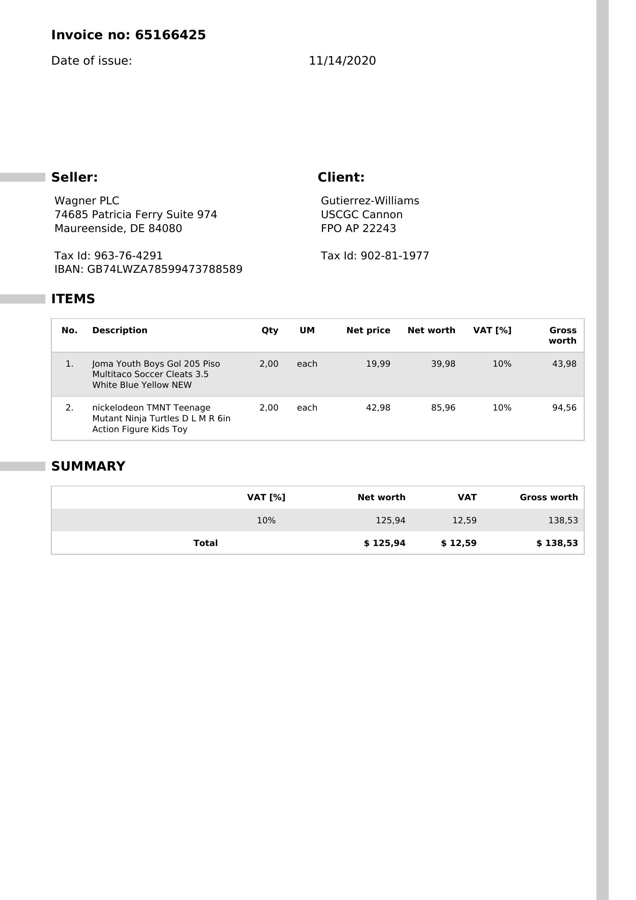

REFERENCE TEXT:
Invoice no: 65166425 Date of issue: 11/14/2020 Seller: Client: Wagner PLC Gutierrez-Williams 74685 Patricia Ferry Suite 974 USCGC Cannon Maureenside_ DE 84080 FPO AP 22243 Tax Id: 963-76-4291 Tax Id: 902-81-1977 IBAN: GBZ4LWZA78599473788589 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth Joma Youth Boys Gol 205 Piso 2,00 each 19,99 39,98 10% 43,98 Multitaco Soccer Cleats 3.5 White Blue Yellow NEW 2 nickelodeon TMNT Teenage 2,00 each 42,98 85,96 10% 94,56 Mutant Ninja Turtles D L M R 6in Action Figure Kids Toy SUMMARY VAT [%] Net worth VAT Gross worth 10% 125,94 12,59 138,53 Total $ 125,94 $ 12,59 $ 138,53

JSON:
{
  "invoice": {
    "client_name": "Gutierrez-Williams",
    "client_address": "USCGC Cannon\nFPO AP 22243",
    "seller_name": "Wagner PLC",
    "seller_address": "74685 Patricia Ferry Suite 974\nMaureenside, DE 84080",
    "invoice_number": "65166425",
    "invoice_date": "11/14/2020",
    "due_date": ""
  },
  "items": [
    {
      "des

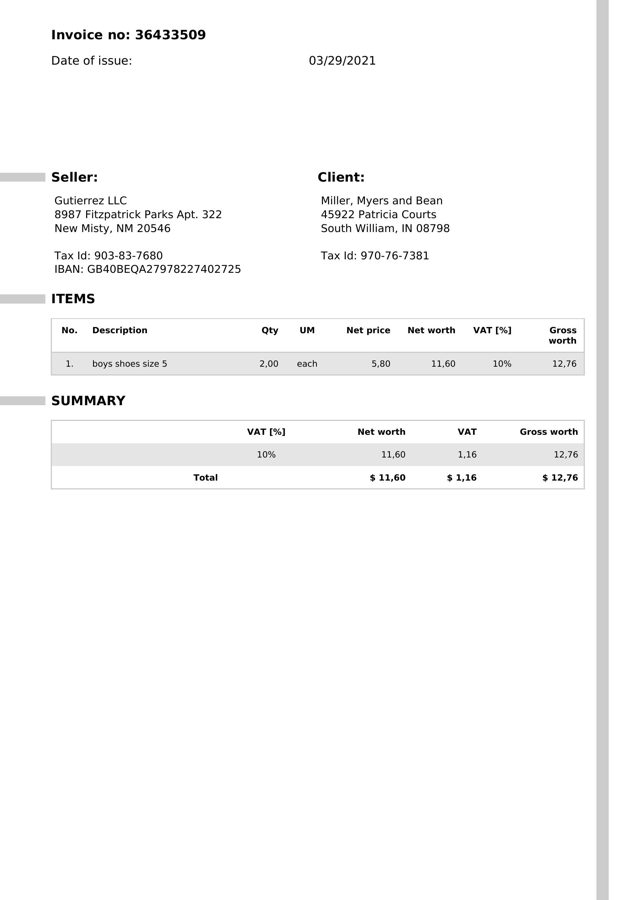

REFERENCE TEXT:
Invoice no: 36433509 Date of issue: 03/29/2021 Seller: Client: Gutierrez LLC Miller, Myers and Bean 8987 Fitzpatrick Parks Apt 322 45922 Patricia Courts New Misty, NM 20546 South William, IN 08798 Tax Id: 903-83-7680 Tax Id: 970-76-7381 IBAN: GBAOBEQA27978227402725 ITEMS No. Description Qty UM Net price Net worth VAT [%] Gross worth 1. boys shoes size 5 2,00 each 5,80 11,60 10% 12,76 SUMMARY VAT [%] Net worth VAT Gross worth 10% 11,60 1,16 12,76 Total $ 11,60 $ 1,16 $ 12,76

JSON:
{
  "invoice": {
    "client_name": "Miller, Myers and Bean",
    "client_address": "45922 Patricia Courts\nSouth William, IN 08798",
    "seller_name": "Gutierrez LLC",
    "seller_address": "8987 Fitzpatrick Parks Apt. 322\nNew Misty, NM 20546",
    "invoice_number": "36433509",
    "invoice_date": "03/29/2021",
    "due_date": ""
  },
  "items": [
    {
      "description": "boys shoes size 5",
      "quantity": "2.00",
      "total_price": "12.76"
    }
  ],
  "subtotal": {
    "tax": "1.1

In [71]:
from IPython.display import display
from PIL import Image

sample = annotated_df.sample(30, random_state=42)

for _, row in sample.head(10).iterrows():
    image = Image.open(row["path"])
    image.thumbnail((700, 900))

    display(image)
    print("REFERENCE TEXT:")
    print(row["ocred_text"][:2000])
    print("\nJSON:")
    print(json.dumps(row["target"], indent=2, ensure_ascii=False))
    print("=" * 100)

### Evaluate PaddleOCR

In [74]:
from time import perf_counter
from tqdm.notebook import tqdm

ocr_sample = annotated_df.sample(
    min(100, len(annotated_df)),
    random_state=42,
).copy()

predictions = []

for _, row in tqdm(ocr_sample.iterrows(), total=len(ocr_sample)):
    started = perf_counter()

    results = list(ocr.predict(row["path"]))
    elapsed = perf_counter() - started

    texts = []
    scores = []
    boxes = []

    for result in results:
        payload = result.json
        data = payload.get("res", payload)

        texts.extend(data.get("rec_texts", []))
        scores.extend(float(x) for x in data.get("rec_scores", []))

        for box in data.get("rec_boxes", []):
            boxes.append(box)

    predictions.append({
        "path": row["path"],
        "paddle_text": "\n".join(texts),
        "paddle_scores": scores,
        "paddle_boxes": boxes,
        "ocr_seconds": elapsed,
    })

predictions_df = pd.DataFrame(predictions)

ocr_sample = ocr_sample.merge(
    predictions_df,
    on="path",
    how="left",
)

  0%|          | 0/100 [00:00<?, ?it/s]

## Metrics

In [84]:
!pip install -q jiwer rapidfuzz torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 18.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.1/366.1 MB 3.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 MB 13.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.5/196.5 MB 7.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 2.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 59.0 MB/s eta 0:00:0000:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
paddlepaddle-gpu 3.3.0 requires nvidia-cublas==13.0.2.14; platform_system == "Linux" and platform_machine == "x86_64", but you have nvidia-cublas 13.1.0.3 which is incompatible.
paddlepaddle-gpu 3.3.0 requires nvidia-cuda-runtime==13.0.88; platform_system == "Linux" and platform_machine =

### CER and WER

In [92]:
import re
from jiwer import cer, wer

def normalize_text(value):
    value = str(value).lower()
    value = re.sub(r"\s+", " ", value)
    return value.strip()

ocr_sample["reference_normalized"] = (
    ocr_sample["ocred_text"].map(normalize_text)
)

ocr_sample["prediction_normalized"] = (
    ocr_sample["paddle_text"].map(normalize_text)
)

ocr_sample["cer"] = ocr_sample.apply(
    lambda row: cer(
        row["reference_normalized"],
        row["prediction_normalized"],
    ),
    axis=1,
)

ocr_sample["wer"] = ocr_sample.apply(
    lambda row: wer(
        row["reference_normalized"],
        row["prediction_normalized"],
    ),
    axis=1,
)

ocr_sample[
    ["cer", "wer", "ocr_seconds"]
].describe()

,cer,wer,ocr_seconds
count,100.000000,100.000000,100.000000
mean,0.018925,0.063037,0.619613
std,0.009344,0.022351,0.106609
min,0.002990,0.017699,0.438148
25%,0.012053,0.049002,0.526196
50%,0.015921,0.060265,0.615612
75%,0.025151,0.078486,0.702425
max,0.044469,0.131868,0.820521


### Corpus CER and WER with TorchMetrics

In [85]:
from torchmetrics.text import CharErrorRate, WordErrorRate

references = ocr_sample["reference_normalized"].tolist()
predictions = ocr_sample["prediction_normalized"].tolist()

corpus_cer = CharErrorRate()(predictions, references).item()
corpus_wer = WordErrorRate()(predictions, references).item()

macro_cer = ocr_sample["cer"].mean()
macro_wer = ocr_sample["wer"].mean()

ocr_error_summary = pd.DataFrame({
    "metric": [
        "Macro CER",
        "Corpus CER",
        "Macro WER",
        "Corpus WER",
    ],
    "value": [
        macro_cer,
        corpus_cer,
        macro_wer,
        corpus_wer,
    ],
})


ocr_error_summary.style.format({
    "value": "{:.2%}",
})

,metric,value
0,Macro CER,1.89%
1,Corpus CER,2.00%
2,Macro WER,6.30%
3,Corpus WER,6.45%


In [81]:
from rapidfuzz.distance import Levenshtein

def normalized_edit_similarity(reference, prediction):
    reference = normalize_text(reference)
    prediction = normalize_text(prediction)

    max_length = max(len(reference), len(prediction))

    if max_length == 0:
        return 1.0

    distance = Levenshtein.distance(reference, prediction)
    return 1 - distance / max_length


ocr_sample["edit_similarity"] = ocr_sample.apply(
    lambda row: normalized_edit_similarity(
        row["ocred_text"],
        row["paddle_text"],
    ),
    axis=1,
)

ocr_sample["edit_similarity"].describe().to_frame()

,edit_similarity
count,100.000000
mean,0.981272
std,0.009208
min,0.956056
25%,0.974885
50%,0.984269
75%,0.988082
max,0.997015


#### Interpretation:

* **1.00** = identical
* **0.98** = approximately 98% similar
* **0.00** = completely different


### Numeric-token precision, recall, and F1

In [82]:
import re
from collections import Counter

NUMBER_PATTERN = re.compile(
    r"\b\d+(?:[.,/-]\d+)*\b"
)

def extract_numeric_tokens(text):
    return NUMBER_PATTERN.findall(str(text).lower())

def multiset_metrics(reference_values, predicted_values):
    reference = Counter(reference_values)
    predicted = Counter(predicted_values)

    true_positive = sum((reference & predicted).values())
    predicted_count = sum(predicted.values())
    reference_count = sum(reference.values())

    precision = (
        true_positive / predicted_count
        if predicted_count
        else float(reference_count == 0)
    )

    recall = (
        true_positive / reference_count
        if reference_count
        else float(predicted_count == 0)
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0.0
    )

    return precision, recall, f1

numeric_metrics = ocr_sample.apply(
    lambda row: multiset_metrics(
        extract_numeric_tokens(row["ocred_text"]),
        extract_numeric_tokens(row["paddle_text"]),
    ),
    axis=1,
)

ocr_sample[
    [
        "numeric_precision",
        "numeric_recall",
        "numeric_f1",
    ]
] = pd.DataFrame(
    numeric_metrics.tolist(),
    index=ocr_sample.index,
)

ocr_sample[
    [
        "numeric_precision",
        "numeric_recall",
        "numeric_f1",
    ]
].describe()

,numeric_precision,numeric_recall,numeric_f1
count,100.000000,100.000000,100.000000
mean,0.962179,0.994749,0.978062
std,0.021245,0.017028,0.015738
min,0.907407,0.895833,0.905263
25%,0.950463,1.000000,0.972413
50%,0.960000,1.000000,0.978260
75%,0.972222,1.000000,0.985915
max,1.000000,1.000000,1.000000


### Paddle confidence diagnostics

In [89]:
import numpy as np

ocr_sample["mean_ocr_confidence"] = (
    ocr_sample["paddle_scores"].map(
        lambda scores: np.mean(scores) if scores else np.nan
    )
)

ocr_sample["min_ocr_confidence"] = (
    ocr_sample["paddle_scores"].map(
        lambda scores: np.min(scores) if scores else np.nan
    )
)

ocr_sample["low_confidence_fraction"] = (
    ocr_sample["paddle_scores"].map(
        lambda scores: (
            np.mean(np.array(scores) < 0.8)
            if scores
            else np.nan
        )
    )
)

# Check whether confidence correlates with actual errors:

confidence_diagnostics = ocr_sample[
    [
        "cer",
        "wer",
        "numeric_f1",
        "field_retention",
        "mean_ocr_confidence",
        "min_ocr_confidence",
        "low_confidence_fraction",
    ]
].corr(method="spearman")

confidence_diagnostics.style.background_gradient(
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

,cer,wer,numeric_f1,field_retention,mean_ocr_confidence,min_ocr_confidence,low_confidence_fraction
cer,1.000000,0.794764,-0.390661,nan,0.330177,0.181222,nan
wer,0.794764,1.000000,-0.270298,nan,0.273410,0.042150,nan
numeric_f1,-0.390661,-0.270298,1.000000,nan,-0.085472,-0.051350,nan
field_retention,nan,nan,nan,nan,nan,nan,nan
mean_ocr_confidence,0.330177,0.273410,-0.085472,nan,1.000000,0.485039,nan
min_ocr_confidence,0.181222,0.042150,-0.051350,nan,0.485039,1.000000,nan
low_confidence_fraction,nan,nan,nan,nan,nan,nan,nan


### Latency percentiles

In [90]:
latency_summary = pd.Series({
    "mean_seconds": ocr_sample["ocr_seconds"].mean(),
    "p50_seconds": ocr_sample["ocr_seconds"].quantile(0.50),
    "p90_seconds": ocr_sample["ocr_seconds"].quantile(0.90),
    "p95_seconds": ocr_sample["ocr_seconds"].quantile(0.95),
    "p99_seconds": ocr_sample["ocr_seconds"].quantile(0.99),
    "pages_per_second": 1 / ocr_sample["ocr_seconds"].mean(),
})

latency_summary.to_frame("value")

,value
mean_seconds,0.619613
p50_seconds,0.615612
p90_seconds,0.766063
p95_seconds,0.782899
p99_seconds,0.805105
pages_per_second,1.613912


### Compare dataset parts

In [91]:
metrics_by_part = (
    ocr_sample
    .groupby("subdir")
    .agg(
        documents=("path", "count"),
        cer=("cer", "mean"),
        wer=("wer", "mean"),
        numeric_f1=("numeric_f1", "mean"),
        field_retention=("field_retention", "mean"),
        mean_confidence=("mean_ocr_confidence", "mean"),
        mean_seconds=("ocr_seconds", "mean"),
        p95_seconds=(
            "ocr_seconds",
            lambda values: values.quantile(0.95),
        ),
    )
    .reset_index()
)

metrics_by_part.style.format({
    "cer": "{:.2%}",
    "wer": "{:.2%}",
    "numeric_f1": "{:.2%}",
    "field_retention": "{:.2%}",
    "mean_confidence": "{:.2%}",
    "mean_seconds": "{:.3f}",
    "p95_seconds": "{:.3f}",
})

,subdir,documents,cer,wer,numeric_f1,field_retention,mean_confidence,mean_seconds,p95_seconds
0,batch1_1,38,1.74%,5.80%,98.10%,100.00%,99.64%,0.599,0.774
1,batch1_2,32,2.02%,6.58%,97.43%,100.00%,99.66%,0.627,0.784
2,batch1_3,30,1.94%,6.64%,97.84%,100.00%,99.67%,0.638,0.767


## Model training

In [97]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [98]:
os.makedirs("/content/drive/MyDrive/ocr", exist_ok=True)

In [99]:
annotated_df.to_parquet(
    "/content/drive/MyDrive/ocr/annotated_invoices.parquet",
    index=False,
)

### FLAN-T5-small

In [95]:
source = annotated_df['ocred_text']
target = annotated_df['target_text']